# Flood forecasting with a CNN-LSTM

DL Lab project by Anhad Mahajan and Aman Sumeet Saxena

We forecast the water depth of a flood 30 minutes ahead, on four floods: Australia, UK, Pakistan and Mozambique.

Parts of this notebook:

1. Load the data
2. Model A (CNN + ConvLSTM)
3. Results of Model A
4. Trend forecast and Model B
5. Capsule network (how bad is the flood)
6. Grad-CAM (where the model looks)
7. Written rules (NeuroSymbolic part)
8. Summary

Run it on a GPU (T4). The saved models are loaded from Google Drive, so nothing is trained again.

## 0. Setup

In [ ]:
# Basic libraries
import os
import json
import gc

# Numbers, tables and plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Averaging filter (used for the ground height) and the confusion matrix plot
from scipy.ndimage import uniform_filter
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Deep learning
import tensorflow as tf
import keras
from keras import layers

# Google Drive
from google.colab import drive

In [ ]:
# Check that a GPU is connected
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Connect Google Drive
drive.mount("/content/drive")

# Folders we read from and save to
PROJECT_DIR = "/content/drive/MyDrive/Flood_project"
PREPARED_DIR = PROJECT_DIR + "/prepared_data"
MODEL_DIR = PROJECT_DIR + "/models"
FIGURE_DIR = PROJECT_DIR + "/model_outputs/figures"
TABLE_DIR = PROJECT_DIR + "/model_outputs/tables"

# Make the output folders if they are missing
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

Mounted at /content/drive


### Settings

In [ ]:
# Two models: each one learns on one flood and is tested on another flood it has never seen
PAIRS = [
    {"name": "30m", "train": "Australia_30m", "test": "UK_30m"},
    {"name": "480m", "train": "Pakistan_480m", "test": "Mozambique_480m"},
]

# Nice names for the four floods
REGION_NAMES = {
    "Australia_30m": "Australia (30 m)",
    "UK_30m": "UK (30 m)",
    "Pakistan_480m": "Pakistan (480 m)",
    "Mozambique_480m": "Mozambique (480 m)",
}

# Time between two maps, in hours
STEP_HOURS = 0.5

# Water above 1 cm counts as wet, above 30 cm counts as flooded
WET_DEPTH_M = 0.01
FLOOD_DEPTH_M = 0.30

# Severity classes: share of normally dry land under more than 30 cm of water
SEVERITY_LIMITS = [0.05, 0.15, 0.30]
SEVERITY_NAMES = ["None", "Minor", "Moderate", "Severe"]

# First 70% of the flood for training, next 15% for checking, last 15% for testing
TRAIN_SHARE = 0.70
VALIDATION_SHARE = 0.15

# The model sees 4 maps and each map has 3 layers (depth, rain, ground height)
INPUT_STEPS = 4
CHANNELS = 3

# Size and number of the small square pieces (tiles) we cut from the maps
TILE_SIZE = 64
TRAIN_TILES = 4000
VALIDATION_TILES = 600
TEST_TILES = 1000

# A tile "changes" if its water moves by more than 1 cm. 1.0 means we keep every tile.
CHANGE_LIMIT_M = 0.01
CALM_TILE_SHARE = 1.0

# Rain is divided by 10 so it is on a similar scale to the other inputs
RAIN_SCALE = 10.0

# Ground height is compared with the average of the 15 x 15 squares around it
TERRAIN_WINDOW = 15

# Training settings
EPOCHS = 20
BATCH_SIZE = 16
LEARNING_RATE = 0.001

# False = load the saved models from Drive. True = train them again.
TRAIN_NEW = False
TRAIN_V2 = False

# Fix the random numbers so every run gives the same result
keras.utils.set_random_seed(42)

# Blue colours for water, grey for dry squares
water_colours = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 256)))
water_colours.set_bad("lightgrey")

### Small helper functions

In [ ]:
def save_figure(fig, name):
    # Save a figure as a PNG on Drive
    fig.savefig(FIGURE_DIR + "/" + name + ".png", dpi=150, bbox_inches="tight")
    print("Saved figure:", name)


def save_table(table, name):
    # Save a table as a CSV on Drive
    table.to_csv(TABLE_DIR + "/" + name + ".csv", index=False)
    print("Saved table:", name)


def show_water(ax, depth_map, top_value):
    # Draw a depth map: dry squares grey, water blue
    water = np.array(depth_map, dtype="float32")
    water[water < WET_DEPTH_M] = np.nan
    return ax.imshow(water, cmap=water_colours, vmin=0, vmax=top_value)


def flooded_share(depth_map, dry_land):
    # Share of the normally dry land that is under more than 30 cm of water
    if dry_land.sum() == 0:
        return 0.0
    return float(np.mean(depth_map[dry_land] > FLOOD_DEPTH_M))


def severity_class(share):
    # Turn a flooded share into a class number: 0 None, 1 Minor, 2 Moderate, 3 Severe
    return int(np.digitize(share, SEVERITY_LIMITS))


def cut_into_tiles(rows, columns):
    # Top-left corner of every full 64 x 64 tile in a map
    corners = []
    for top in range(0, rows - TILE_SIZE + 1, TILE_SIZE):
        for left in range(0, columns - TILE_SIZE + 1, TILE_SIZE):
            corners.append((top, left))
    return corners

## 1. Load the data

For every 30-minute step the model gets 3 layers:

- water depth (metres)
- rain that has already fallen in the last 30 minutes
- local ground height: how much higher or lower a square is than the squares around it

In [ ]:
def load_region(dataset):
    # Load one flood from Drive and prepare its layers
    folder = PREPARED_DIR + "/" + dataset

    # Water depth and rain for every 30-minute step (missing values become 0)
    depth = np.nan_to_num(np.load(folder + "/depth.npy"), copy=False)
    rain = np.nan_to_num(np.load(folder + "/rain.npy"), copy=False)

    # Ground height, with missing squares set to the average height
    terrain = np.load(folder + "/terrain.npy").astype("float32")
    terrain[np.isnan(terrain)] = np.nanmean(terrain)

    # Local ground height: positive = higher than the area around it, negative = a dip
    local_height = terrain - uniform_filter(terrain, size=TERRAIN_WINDOW)
    local_height = local_height / max(local_height.std(), 1e-6)

    # Rivers and lakes (so the severity only counts land that is normally dry)
    permanent_water = np.load(folder + "/permanent_water.npy").astype(bool)

    # Map details
    with open(folder + "/map_info.json") as file:
        info = json.load(file)

    number_of_maps = depth.shape[0]

    region = {}
    region["depth"] = depth
    region["rain"] = rain
    region["local_height"] = local_height.astype("float32")
    region["dry_land"] = ~permanent_water
    region["info"] = info
    region["number_of_maps"] = number_of_maps
    region["train_end"] = int(TRAIN_SHARE * number_of_maps)
    region["validation_end"] = int((TRAIN_SHARE + VALIDATION_SHARE) * number_of_maps)
    return region

In [ ]:
# Load all four floods (takes a few minutes)
regions = {}

for dataset in REGION_NAMES:
    regions[dataset] = load_region(dataset)
    print(dataset, regions[dataset]["depth"].shape)

Australia_30m (481, 1073, 1073)
UK_30m (145, 170, 275)
Pakistan_480m (673, 810, 441)
Mozambique_480m (289, 151, 138)


In [ ]:
# The first map we can forecast: we need 4 earlier maps and the rain before them
FIRST_TARGET = INPUT_STEPS + 1

# Table of which hours are used for training, checking and testing
split_rows = []

for pair in PAIRS:
    train_region = regions[pair["train"]]

    train_hours = str(FIRST_TARGET * STEP_HOURS) + " - " + str(train_region["train_end"] * STEP_HOURS)
    check_hours = str(train_region["train_end"] * STEP_HOURS) + " - " + str(train_region["validation_end"] * STEP_HOURS)
    test_hours = str(train_region["validation_end"] * STEP_HOURS) + " - " + str(train_region["number_of_maps"] * STEP_HOURS)

    split_rows.append({"Model": pair["name"], "Region": REGION_NAMES[pair["train"]],
                       "Train (hours)": train_hours, "Validation (hours)": check_hours, "Test (hours)": test_hours})

    split_rows.append({"Model": pair["name"], "Region": REGION_NAMES[pair["test"]],
                       "Train (hours)": "-", "Validation (hours)": "-", "Test (hours)": "whole flood (never seen)"})

split_table = pd.DataFrame(split_rows)
display(split_table)
save_table(split_table, "01_data_split")

,Model,Region,Train (hours),Validation (hours),Test (hours)
0,30m,Australia (30 m),2.5 - 168.0,168.0 - 204.0,204.0 - 240.5
1,30m,UK (30 m),-,-,whole flood (never seen)
2,480m,Pakistan (480 m),2.5 - 235.5,235.5 - 286.0,286.0 - 336.5
3,480m,Mozambique (480 m),-,-,whole flood (never seen)


Saved table: 01_data_split


In [ ]:
def make_input(region, last_step, top=0, left=0, height=None, width=None):
    # Build one model input: the 4 maps up to last_step, each with depth, past rain and ground height
    # Without a tile position, the whole map is used

    if height is None:
        height = region["depth"].shape[1]
        width = region["depth"].shape[2]

    maps = []

    for step in range(last_step - INPUT_STEPS + 1, last_step + 1):
        depth = region["depth"][step, top:top + height, left:left + width]

        # rain[step - 1] is the rain that fell before this map, so it has already happened
        rain = region["rain"][step - 1, top:top + height, left:left + width].astype("float32") / RAIN_SCALE

        height_map = region["local_height"][top:top + height, left:left + width]

        # Stack the 3 layers of this map
        maps.append(np.stack([depth, rain, height_map], axis=-1))

    # Shape: (4 maps, height, width, 3 layers)
    return np.stack(maps).astype("float32")

In [ ]:
def make_training_tiles(region, first_target, last_target, count):
    # Cut random 64 x 64 tiles at random times; the answer is the depth map 30 minutes later
    rows = region["depth"].shape[1]
    columns = region["depth"].shape[2]

    inputs = []
    targets = []
    positions = []

    while len(inputs) < count:
        # Pick a random time and a random place
        target_step = np.random.randint(first_target, last_target)
        top = np.random.randint(0, rows - TILE_SIZE + 1)
        left = np.random.randint(0, columns - TILE_SIZE + 1)

        target = region["depth"][target_step, top:top + TILE_SIZE, left:left + TILE_SIZE]
        last = region["depth"][target_step - 1, top:top + TILE_SIZE, left:left + TILE_SIZE]

        # Skip some calm tiles (with CALM_TILE_SHARE = 1.0 nothing is skipped)
        water_changes = np.abs(target - last).max() > CHANGE_LIMIT_M
        if not water_changes and np.random.rand() > CALM_TILE_SHARE:
            continue

        inputs.append(make_input(region, target_step - 1, top, left, TILE_SIZE, TILE_SIZE))
        targets.append(target[:, :, None])
        positions.append((target_step, top, left))

    return np.array(inputs), np.array(targets, dtype="float32"), positions

In [ ]:
def make_test_tiles(region, first_target, last_target, max_count):
    # Cut the maps into a regular grid of 64 x 64 tiles and pick some of them at random
    rows = region["depth"].shape[1]
    columns = region["depth"].shape[2]

    # Every (time, tile) pair
    all_positions = []
    for target_step in range(first_target, last_target):
        for top, left in cut_into_tiles(rows, columns):
            all_positions.append((target_step, top, left))

    # Pick max_count of them at random
    picked = np.random.permutation(len(all_positions))[:max_count]

    positions = []
    inputs = []
    targets = []

    for number in picked:
        target_step, top, left = all_positions[number]
        positions.append((target_step, top, left))
        inputs.append(make_input(region, target_step - 1, top, left, TILE_SIZE, TILE_SIZE))
        targets.append(region["depth"][target_step, top:top + TILE_SIZE, left:left + TILE_SIZE, None])

    return np.array(inputs), np.array(targets, dtype="float32"), positions

In [ ]:
# Make the training and checking tiles for both models
tiles = {}

for pair in PAIRS:
    region = regions[pair["train"]]

    train_inputs, train_targets, train_positions = make_training_tiles(
        region, FIRST_TARGET, region["train_end"], TRAIN_TILES)

    validation_inputs, validation_targets, validation_positions = make_training_tiles(
        region, region["train_end"], region["validation_end"], VALIDATION_TILES)

    tiles[pair["name"]] = {
        "train_inputs": train_inputs,
        "train_targets": train_targets,
        "train_positions": train_positions,
        "validation_inputs": validation_inputs,
        "validation_targets": validation_targets,
        "validation_positions": validation_positions,
    }

    print(pair["name"], "training tiles:", train_inputs.shape, "checking tiles:", validation_inputs.shape)

30m training tiles: (4000, 4, 64, 64, 3) checking tiles: (600, 4, 64, 64, 3)
480m training tiles: (4000, 4, 64, 64, 3) checking tiles: (600, 4, 64, 64, 3)


## 2. Model A: CNN + ConvLSTM

- 2 CNN layers look at each of the 4 maps and find shapes (water edges, slopes, rain patches)
- a ConvLSTM layer reads the 4 maps in order and remembers how the water moved
- a small decoder turns that memory into the change in depth over the next 30 minutes
- next map = last map + predicted change (never below 0)

The last layer starts at zero, so before training the model simply copies the last map.

In [ ]:
def build_forecaster(height=TILE_SIZE, width=TILE_SIZE):
    # Model A: CNN + ConvLSTM that predicts the depth map 30 minutes ahead

    # Input: 4 maps, each height x width, with 3 layers
    inputs = keras.Input(shape=(INPUT_STEPS, height, width, CHANNELS), name="past_maps")

    # CNN: the same 2 convolution layers are used on each of the 4 maps
    x = layers.TimeDistributed(layers.Conv2D(16, 3, padding="same", activation="relu"), name="cnn_1")(inputs)
    x = layers.TimeDistributed(layers.Conv2D(16, 3, padding="same", activation="relu"), name="cnn_2")(x)

    # ConvLSTM: reads the 4 maps in order and keeps a memory map
    memory = layers.ConvLSTM2D(32, 3, padding="same", name="memory")(x)

    # Decoder: memory -> predicted change in depth (the last layer starts at zero)
    x = layers.Conv2D(16, 3, padding="same", activation="relu", name="decoder")(memory)
    change = layers.Conv2D(1, 1, kernel_initializer="zeros", name="depth_change")(x)

    # Next map = last depth map + change, and never below 0
    last_depth = inputs[:, -1, :, :, 0:1]
    next_depth = layers.ReLU(name="next_depth")(layers.Add()([last_depth, change]))

    return keras.Model(inputs, next_depth, name="cnn_lstm_forecaster")


def forecaster_for_whole_map(trained_forecaster, region):
    # Build the same model at the size of a whole map and copy in the trained weights
    height = region["depth"].shape[1]
    width = region["depth"].shape[2]
    whole_map_forecaster = build_forecaster(height, width)
    whole_map_forecaster.set_weights(trained_forecaster.get_weights())
    return whole_map_forecaster


# Show the layers and the number of parameters
build_forecaster().summary()

Model: "cnn_lstm_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ past_maps           │ (None, 4, 64, 64, │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_1               │ (None, 4, 64, 64, │        448 │ past_maps[0][0]   │
│ (TimeDistributed)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_2               │ (None, 4, 64, 64, │      2,320 │ cnn_1[0][0]       │
│ (TimeDistributed)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ memory (ConvLSTM2D) │ (None, 64, 64,    │     55,424 │ cnn_2[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder (Conv2D)    │ (None, 64, 64,    │      4,624 │ memory[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 64, 64, 1) │          0 │ past_maps[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depth_change        │ (None, 64, 64, 1) │         17 │ decoder[0][0]     │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64, 1) │          0 │ get_item[0][0],   │
│                     │                   │            │ depth_change[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_depth (ReLU)   │ (None, 64, 64, 1) │          0 │ add[0][0]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 62,833 (245.44 KB)

 Trainable params: 62,833 (245.44 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Load (or train) Model A for each map scale
forecasters = {}
histories = {}

for pair in PAIRS:
    data = tiles[pair["name"]]
    weights_path = MODEL_DIR + "/forecaster_" + pair["name"] + ".weights.h5"

    forecaster = build_forecaster()
    forecaster.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="mse")

    if TRAIN_NEW or not os.path.exists(weights_path):
        print("Training Model A", pair["name"])

        # Stop when the checking error has not improved for 4 epochs, and keep the best weights
        stop_early = keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)

        history = forecaster.fit(
            data["train_inputs"], data["train_targets"],
            validation_data=(data["validation_inputs"], data["validation_targets"]),
            epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[stop_early], verbose=2)

        histories[pair["name"]] = history.history
        forecaster.save_weights(weights_path)
    else:
        print("Loading Model A", pair["name"])
        forecaster.load_weights(weights_path)

    forecasters[pair["name"]] = forecaster

Loading Model A 30m
Loading Model A 480m


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
# Training curves (only shown when the models were trained in this run)
if len(histories) > 0:
    fig, axes = plt.subplots(1, len(histories), figsize=(14, 4.5), squeeze=False)

    for ax, name in zip(axes[0], histories):
        history = histories[name]
        epochs = np.arange(1, len(history["loss"]) + 1)

        # Square root of the error, in centimetres
        ax.plot(epochs, 100 * np.sqrt(history["loss"]), "o-", label="training tiles")
        ax.plot(epochs, 100 * np.sqrt(history["val_loss"]), "o-", label="checking tiles")

        ax.set_title(name + " model")
        ax.set_xlabel("epoch")
        ax.set_ylabel("typical error (cm)")
        ax.legend()

    save_figure(fig, "02_training_progress")
    plt.show()

## 3. Results of Model A on whole maps

We compare every forecast with **copy the last map** (the water stays where it is).

- **Typical error (RMSE)**: average error per square, in centimetres
- **Skill** = 1 - (model error / copy error). 0 = same as copying, 1 = perfect, below 0 = worse than copying
- **CSI**: how well the flooded areas (above 30 cm) match. 1 = perfect

### 3a. Water-balance rule

Almost all rain stays on the ground in these simulations (a little water crosses the edge of the map). So over the whole map, roughly:

    average rise of the water in 30 minutes (mm) = rain (mm per hour) x 0.5 hours

The rule fixes only the total water in the forecast. Where the water goes is still decided by the network.
It only uses rain that has already fallen. It helps Model A; for Model B (part 4) it changes almost nothing.

First we check how well this law holds in the data.

Saved figure: 03_water_balance_check


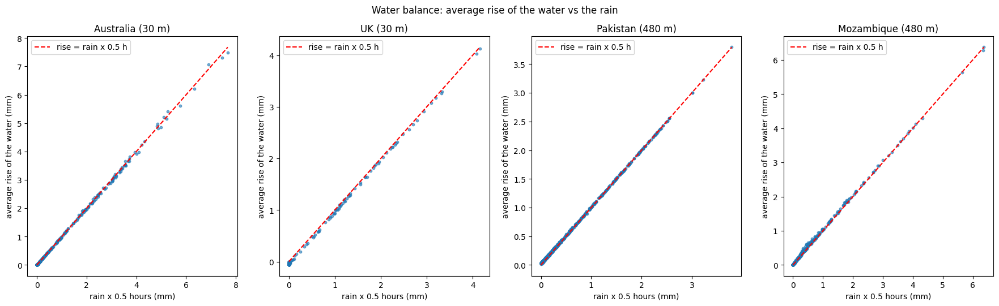

,Region,Total rise / total (rain x 0.5 h),Correlation with rain at the same time,Correlation with rain of the 30 min before
0,Australia (30 m),0.999,1.0,0.925
1,UK (30 m),0.946,1.0,0.945
2,Pakistan (480 m),1.028,1.0,0.969
3,Mozambique (480 m),1.045,1.0,0.929


Saved table: 03_water_balance_check


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
balance_rows = []

for ax, dataset in zip(axes, REGION_NAMES):
    region = regions[dataset]

    # Average depth of the whole map at every step (mm), and how much it rises each 30 minutes
    average_depth_mm = 1000 * region["depth"].mean(axis=(1, 2), dtype="float64")
    rise_mm = np.diff(average_depth_mm)

    # Rain falling at the same time, times half an hour
    rain_now_mm = 0.5 * region["rain"][:len(rise_mm)].mean(axis=(1, 2), dtype="float64")

    # Rain of the 30 minutes before (the only rain a forecast is allowed to use)
    rain_before_mm = np.concatenate([[0.0], rain_now_mm[:-1]])

    # Each dot is one step; the red line is the law
    ax.scatter(rain_now_mm, rise_mm, s=10, alpha=0.6)
    top = max(rain_now_mm.max(), rise_mm.max())
    ax.plot([0, top], [0, top], "r--", label="rise = rain x 0.5 h")

    ax.set_title(REGION_NAMES[dataset])
    ax.set_xlabel("rain x 0.5 hours (mm)")
    ax.set_ylabel("average rise of the water (mm)")
    ax.legend()

    balance_rows.append({
        "Region": REGION_NAMES[dataset],
        "Total rise / total (rain x 0.5 h)": round(rise_mm.sum() / max(rain_now_mm.sum(), 1e-9), 3),
        "Correlation with rain at the same time": round(np.corrcoef(rain_now_mm, rise_mm)[0, 1], 3),
        "Correlation with rain of the 30 min before": round(np.corrcoef(rain_before_mm, rise_mm)[0, 1], 3),
    })

fig.suptitle("Water balance: average rise of the water vs the rain")
save_figure(fig, "03_water_balance_check")
plt.show()

balance_table = pd.DataFrame(balance_rows)
display(balance_table)
save_table(balance_table, "03_water_balance_check")

In [ ]:
def apply_water_balance(predicted, last, past_rain):
    # Shift the forecast so the total rise of the water matches the rain of the last 30 minutes

    predicted_change = predicted - last

    # Rise allowed by the rain, in metres (mm per hour x 0.5 hours / 1000)
    allowed_rise = 0.5 * float(np.mean(past_rain)) / 1000

    # Extra water the network added (positive) or rain water it missed (negative)
    extra_water = (float(np.mean(predicted_change)) - allowed_rise) * predicted.size

    corrected = predicted.copy()

    if extra_water < 0:
        # Missing rain water: rain falls everywhere, so add it to every square
        corrected = corrected - extra_water / predicted.size
    else:
        # Extra water: take it away only from squares that have water
        wet = corrected > WET_DEPTH_M
        if wet.sum() > 0:
            corrected[wet] = corrected[wet] - extra_water / wet.sum()

    # Depth can't be negative
    return np.maximum(corrected, 0)

In [ ]:
def critical_success_index(predicted, true):
    # Of the squares flooded in the forecast or in reality, the share where both agree
    predicted_flooded = predicted > FLOOD_DEPTH_M
    true_flooded = true > FLOOD_DEPTH_M

    hits = np.sum(predicted_flooded & true_flooded)
    misses = np.sum(~predicted_flooded & true_flooded)
    false_alarms = np.sum(predicted_flooded & ~true_flooded)

    # Nothing flooded anywhere: the score is undefined, so this step is skipped
    if hits + misses + false_alarms == 0:
        return np.nan

    return hits / (hits + misses + false_alarms)


def evaluate_region(forecaster, region, first_target, last_target):
    # Forecast every whole map, with and without the water rule, and compare with copying
    rows = []
    example = None
    biggest_change = -1.0

    for target_step in range(first_target, last_target):
        model_input = make_input(region, target_step - 1)[None]
        predicted = forecaster(model_input, training=False).numpy()[0, :, :, 0]

        true = region["depth"][target_step]
        last = region["depth"][target_step - 1]

        # Rain of the last 30 minutes (back in mm per hour) and the corrected forecast
        past_rain = model_input[0, -1, :, :, 1] * RAIN_SCALE
        corrected = apply_water_balance(predicted, last, past_rain)

        rows.append({
            "hours": target_step * STEP_HOURS,
            "model_squared_error": float(np.sum((predicted - true) ** 2)),
            "rule_squared_error": float(np.sum((corrected - true) ** 2)),
            "copy_squared_error": float(np.sum((last - true) ** 2)),
            "cells": true.size,
            "model_csi": critical_success_index(predicted, true),
            "rule_csi": critical_success_index(corrected, true),
            "copy_csi": critical_success_index(last, true),
        })

        # Keep the step where the water changes the most, for the pictures
        total_change = float(np.abs(true - last).sum())
        if total_change > biggest_change:
            biggest_change = total_change
            example = {"step": target_step, "last": last, "true": true, "predicted": predicted, "corrected": corrected}

    return pd.DataFrame(rows), example

In [ ]:
# Test Model A on whole maps in all four floods
evaluations = {}
examples = {}
whole_map_forecasters = {}

for pair in PAIRS:
    train_region = regions[pair["train"]]
    test_region = regions[pair["test"]]

    # Copy the trained weights into models the size of each whole map
    whole_map_forecasters[pair["train"]] = forecaster_for_whole_map(forecasters[pair["name"]], train_region)
    whole_map_forecasters[pair["test"]] = forecaster_for_whole_map(forecasters[pair["name"]], test_region)

    # Training flood: only the last 15% (never used in training)
    evaluations[pair["train"]], examples[pair["train"]] = evaluate_region(
        whole_map_forecasters[pair["train"]], train_region, train_region["validation_end"], train_region["number_of_maps"])

    # Test flood: the whole flood (never seen)
    evaluations[pair["test"]], examples[pair["test"]] = evaluate_region(
        whole_map_forecasters[pair["test"]], test_region, FIRST_TARGET, test_region["number_of_maps"])

    print(pair["name"], "done")

30m done
480m done


In [ ]:
# Results table for Model A
result_rows = []

for pair in PAIRS:
    for dataset, part in [(pair["train"], "unseen time (last 15%)"), (pair["test"], "never-seen region")]:
        evaluation = evaluations[dataset]
        cells = evaluation["cells"].sum()
        copy_error = evaluation["copy_squared_error"].sum()
        model_error = evaluation["model_squared_error"].sum()
        rule_error = evaluation["rule_squared_error"].sum()

        result_rows.append({
            "Region": REGION_NAMES[dataset],
            "Tested on": part,
            "Forecasts": len(evaluation),
            "Copy last map: error (cm)": round(100 * np.sqrt(copy_error / cells), 3),
            "CNN-LSTM: error (cm)": round(100 * np.sqrt(model_error / cells), 3),
            "CNN-LSTM + water rule: error (cm)": round(100 * np.sqrt(rule_error / cells), 3),
            "CNN-LSTM: skill": round(1 - model_error / copy_error, 3),
            "CNN-LSTM + water rule: skill": round(1 - rule_error / copy_error, 3),
            "Copy last map: CSI": round(evaluation["copy_csi"].mean(), 4),
            "CNN-LSTM + water rule: CSI": round(evaluation["rule_csi"].mean(), 4),
        })

result_table = pd.DataFrame(result_rows)
display(result_table)
save_table(result_table, "03_forecast_results")

,Region,Tested on,Forecasts,Copy last map: error (cm),CNN-LSTM: error (cm),CNN-LSTM + water rule: error (cm),CNN-LSTM: skill,CNN-LSTM + water rule: skill,Copy last map: CSI,CNN-LSTM + water rule: CSI
0,Australia (30 m),unseen time (last 15%),73,0.112,0.175,0.147,-1.449,-0.710,0.9995,0.9992
1,UK (30 m),never-seen region,140,0.520,0.433,0.429,0.305,0.320,0.9888,0.9919
2,Pakistan (480 m),unseen time (last 15%),101,0.103,0.084,0.080,0.345,0.404,0.9993,0.9994
3,Mozambique (480 m),never-seen region,284,0.548,0.505,0.498,0.150,0.172,0.9678,0.9732


Saved table: 03_forecast_results


Saved figure: 03_skill_per_region


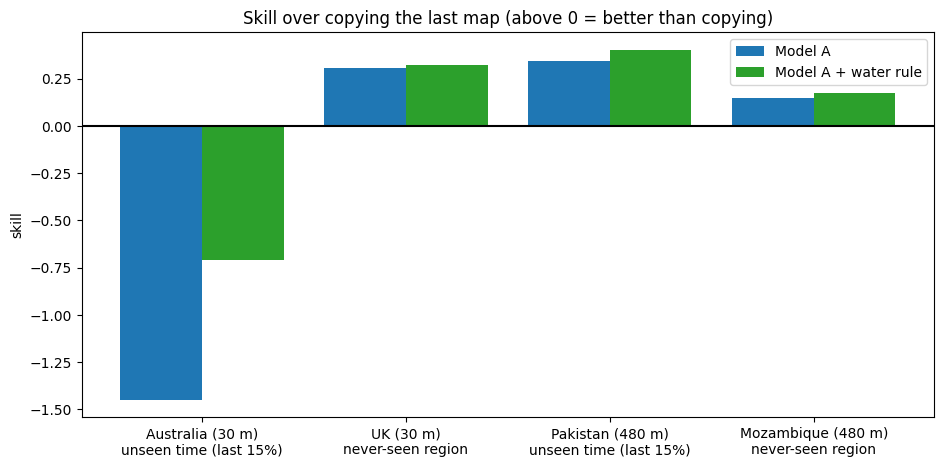

In [ ]:
# Bar chart of the skill of Model A, with and without the water rule
fig, ax = plt.subplots(figsize=(11, 5))

labels = []
for region, part in zip(result_table["Region"], result_table["Tested on"]):
    labels.append(region + "\n" + part)

positions = np.arange(len(labels))
ax.bar(positions - 0.2, result_table["CNN-LSTM: skill"], width=0.4, color="tab:blue", label="Model A")
ax.bar(positions + 0.2, result_table["CNN-LSTM + water rule: skill"], width=0.4, color="tab:green", label="Model A + water rule")
ax.axhline(0, color="black")

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_title("Skill over copying the last map (above 0 = better than copying)")
ax.set_ylabel("skill")
ax.legend()

save_figure(fig, "03_skill_per_region")
plt.show()

Saved figure: 03_error_over_time


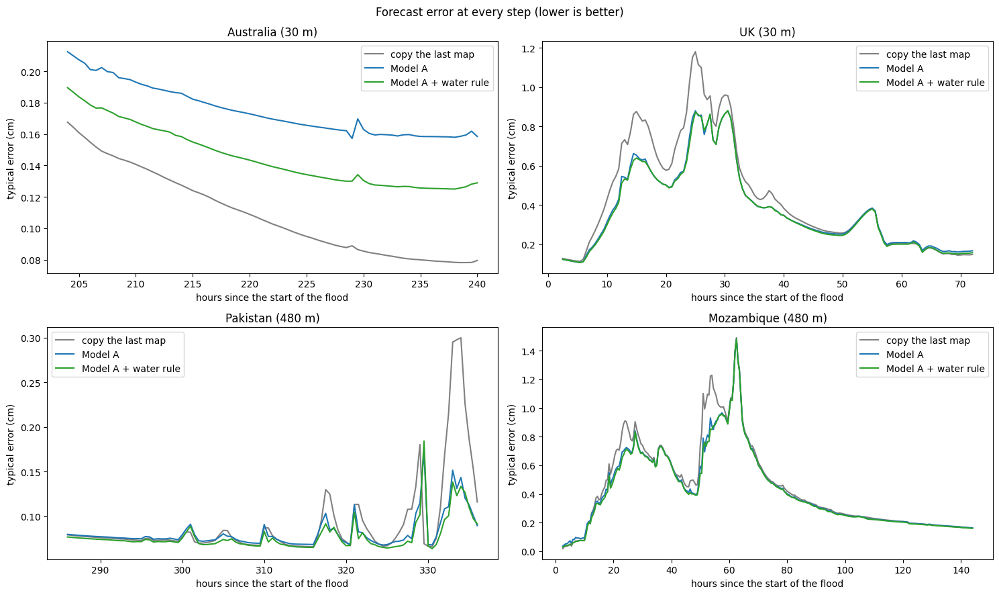

In [ ]:
# Error at every step of the test period
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ax, dataset in zip(axes.flat, REGION_NAMES):
    evaluation = evaluations[dataset]
    hours = evaluation["hours"]
    cells = evaluation["cells"]

    ax.plot(hours, 100 * np.sqrt(evaluation["copy_squared_error"] / cells), color="grey", label="copy the last map")
    ax.plot(hours, 100 * np.sqrt(evaluation["model_squared_error"] / cells), color="tab:blue", label="Model A")
    ax.plot(hours, 100 * np.sqrt(evaluation["rule_squared_error"] / cells), color="tab:green", label="Model A + water rule")

    ax.set_title(REGION_NAMES[dataset])
    ax.set_xlabel("hours since the start of the flood")
    ax.set_ylabel("typical error (cm)")
    ax.legend()

fig.suptitle("Forecast error at every step (lower is better)")
plt.tight_layout()
save_figure(fig, "03_error_over_time")
plt.show()

### Forecast maps

One row per flood, at the moment the water changes the most. In the change maps, blue = water rising and red = water falling.

Saved figure: 03_forecast_maps


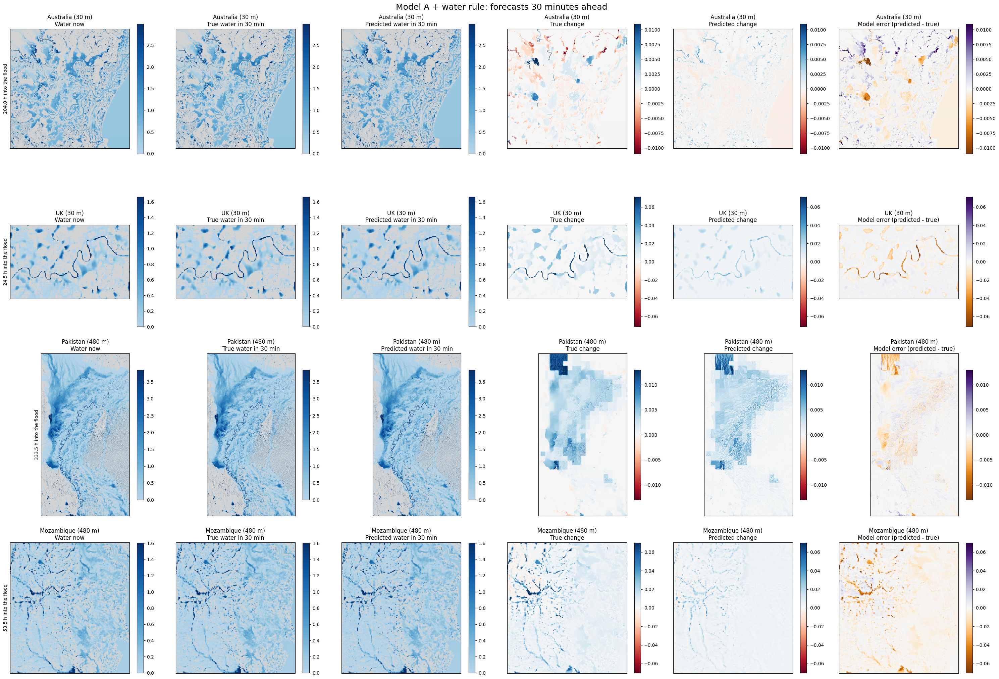

In [ ]:
column_titles = ["Water now", "True water in 30 min", "Predicted water in 30 min",
                 "True change", "Predicted change", "Model error (predicted - true)"]

fig, axes = plt.subplots(4, 6, figsize=(30, 21))

for row, dataset in enumerate(REGION_NAMES):
    example = examples[dataset]

    # Same colour range for the water maps, and for the change maps
    top_depth = max(np.percentile(example["true"], 99), 0.1)
    true_change = example["true"] - example["last"]
    top_change = max(np.percentile(np.abs(true_change), 99.5), 0.01)

    # The predicted columns show the forecast after the water rule
    pictures = [
        show_water(axes[row, 0], example["last"], top_depth),
        show_water(axes[row, 1], example["true"], top_depth),
        show_water(axes[row, 2], example["corrected"], top_depth),
        axes[row, 3].imshow(true_change, cmap="RdBu", vmin=-top_change, vmax=top_change),
        axes[row, 4].imshow(example["corrected"] - example["last"], cmap="RdBu", vmin=-top_change, vmax=top_change),
        axes[row, 5].imshow(example["corrected"] - example["true"], cmap="PuOr", vmin=-top_change, vmax=top_change),
    ]

    for column in range(6):
        axes[row, column].set_title(REGION_NAMES[dataset] + "\n" + column_titles[column])
        fig.colorbar(pictures[column], ax=axes[row, column], shrink=0.8)

    axes[row, 0].set_ylabel(str(example["step"] * STEP_HOURS) + " h into the flood")

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Model A + water rule: forecasts 30 minutes ahead", fontsize=18)
plt.tight_layout()
save_figure(fig, "03_forecast_maps")
plt.show()

## 4. Trend forecast and Model B

**Trend forecast**: the water keeps changing the way it changed in the last 30 minutes.

    next map = last map + beta x (last map - map 30 minutes before)        (never below 0)

beta is one number fitted on the training part only. There is no network.

**Model B**: the same CNN + ConvLSTM as Model A, but it starts from the trend forecast and only learns a small correction (in centimetres).
Before training, Model B is exactly the trend forecast.

In [ ]:
def fit_trend_factor(region, first_target, last_target):
    # Find beta: how much of the last 30-minute change carries on into the next 30 minutes
    top = 0.0
    bottom = 0.0

    for step in range(first_target, last_target):
        last = region["depth"][step - 1]
        previous_change = (last - region["depth"][step - 2]).astype("float64")
        next_change = (region["depth"][step] - last).astype("float64")

        top += float(np.sum(previous_change * next_change))
        bottom += float(np.sum(previous_change ** 2))

    return top / bottom


def score_simple_forecasts(region, first_target, last_target, trend_factor):
    # Skill of the simple forecasts against copying the last map
    errors = {"copy": 0.0, "trend": 0.0, "copy + rule": 0.0, "trend + rule": 0.0}

    for step in range(first_target, last_target):
        true = region["depth"][step]
        last = region["depth"][step - 1]
        change = last - region["depth"][step - 2]

        # Rain of the 30 minutes before the last map
        past_rain = region["rain"][step - 2].astype("float32")

        trend = np.maximum(last + trend_factor * change, 0)

        forecasts = {
            "copy": last,
            "trend": trend,
            "copy + rule": apply_water_balance(last, last, past_rain),
            "trend + rule": apply_water_balance(trend, last, past_rain),
        }

        for name in forecasts:
            errors[name] += float(np.sum((forecasts[name] - true) ** 2, dtype="float64"))

    skills = {}
    for name in ["trend", "copy + rule", "trend + rule"]:
        skills[name] = round(1 - errors[name] / errors["copy"], 3)
    return skills


# Fit beta for each model, on the training part of its training flood
trend_factors = {}

for pair in PAIRS:
    train_region = regions[pair["train"]]
    trend_factors[pair["name"]] = fit_trend_factor(train_region, FIRST_TARGET, train_region["train_end"])

print("Trend numbers (beta):", trend_factors)

Trend numbers (beta): {'30m': 0.9207325646981332, '480m': 0.9484679530902703}


In [ ]:
# Score the simple forecasts on the same test parts as Model A
simple_rows = []

for pair in PAIRS:
    train_region = regions[pair["train"]]
    test_region = regions[pair["test"]]

    parts = [
        (pair["train"], "unseen time (last 15%)", train_region["validation_end"], train_region["number_of_maps"]),
        (pair["test"], "never-seen region", FIRST_TARGET, test_region["number_of_maps"]),
    ]

    for dataset, part, first_target, last_target in parts:
        skills = score_simple_forecasts(regions[dataset], first_target, last_target, trend_factors[pair["name"]])
        model_a_row = result_table[result_table["Region"] == REGION_NAMES[dataset]].iloc[0]

        simple_rows.append({
            "Region": REGION_NAMES[dataset],
            "Tested on": part,
            "Trend number": round(trend_factors[pair["name"]], 3),
            "Skill: trend": skills["trend"],
            "Skill: trend + rule": skills["trend + rule"],
            "Skill: copy + rule": skills["copy + rule"],
            "Skill: Model A": model_a_row["CNN-LSTM: skill"],
            "Skill: Model A + rule": model_a_row["CNN-LSTM + water rule: skill"],
        })

simple_table = pd.DataFrame(simple_rows)
display(simple_table)
save_table(simple_table, "04_simple_forecasts")

,Region,Tested on,Trend number,Skill: trend,Skill: trend + rule,Skill: copy + rule,Skill: Model A,Skill: Model A + rule
0,Australia (30 m),unseen time (last 15%),0.921,0.990,0.990,0.000,-1.449,-0.710
1,UK (30 m),never-seen region,0.921,0.947,0.947,0.053,0.305,0.320
2,Pakistan (480 m),unseen time (last 15%),0.948,0.908,0.905,0.142,0.345,0.404
3,Mozambique (480 m),never-seen region,0.948,0.942,0.942,0.051,0.150,0.172


Saved table: 04_simple_forecasts


In [ ]:
# Model B counts its correction in centimetres
CHANGE_UNIT = 0.01


def build_forecaster_v2(trend_factor, height=TILE_SIZE, width=TILE_SIZE):
    # Model B: same layers as Model A, but it starts from the trend forecast

    inputs = keras.Input(shape=(INPUT_STEPS, height, width, CHANNELS), name="past_maps")

    # Same CNN + ConvLSTM + decoder as Model A
    x = layers.TimeDistributed(layers.Conv2D(16, 3, padding="same", activation="relu"), name="cnn_1")(inputs)
    x = layers.TimeDistributed(layers.Conv2D(16, 3, padding="same", activation="relu"), name="cnn_2")(x)
    memory = layers.ConvLSTM2D(32, 3, padding="same", name="memory")(x)
    x = layers.Conv2D(16, 3, padding="same", activation="relu", name="decoder")(memory)
    correction = layers.Conv2D(1, 1, kernel_initializer="zeros", name="correction")(x)

    # Trend forecast = last map + beta x last change (never below 0)
    last_depth = inputs[:, -1, :, :, 0:1]
    previous_depth = inputs[:, -2, :, :, 0:1]
    last_change = layers.Subtract()([last_depth, previous_depth])
    trend = layers.ReLU()(layers.Add()([last_depth, layers.Rescaling(float(trend_factor))(last_change)]))

    # Next map = trend + correction in centimetres (never below 0)
    next_depth = layers.ReLU(name="next_depth")(layers.Add()([trend, layers.Rescaling(CHANGE_UNIT)(correction)]))

    return keras.Model(inputs, next_depth, name="cnn_lstm_forecaster_v2")


def loss_in_cm(true, predicted):
    # Mean squared error in centimetres (in metres the numbers are tiny)
    return tf.reduce_mean(tf.square((true - predicted) / CHANGE_UNIT))


def v2_for_whole_map(trained_forecaster, region, trend_factor):
    # Build Model B at the size of a whole map and copy in the trained weights
    whole_map_forecaster = build_forecaster_v2(trend_factor, region["depth"].shape[1], region["depth"].shape[2])
    whole_map_forecaster.set_weights(trained_forecaster.get_weights())
    return whole_map_forecaster


# Check: before training, Model B must give exactly the trend forecast
check_model = build_forecaster_v2(trend_factors["30m"])
sample = tiles["30m"]["validation_inputs"][:50]

last_maps = sample[:, -1, :, :, 0:1]
previous_maps = sample[:, -2, :, :, 0:1]
expected = np.maximum(last_maps + trend_factors["30m"] * (last_maps - previous_maps), 0)
got = check_model.predict(sample, verbose=0)

print("Parameters:", check_model.count_params())
print("Biggest difference from the trend forecast:", float(np.abs(got - expected).max()))

Parameters: 62833
Biggest difference from the trend forecast: 0.0


In [ ]:
# Load (or train) Model B for each map scale
v2_forecasters = {}

for pair in PAIRS:
    data = tiles[pair["name"]]
    weights_path = MODEL_DIR + "/forecaster_v2_" + pair["name"] + ".weights.h5"

    forecaster = build_forecaster_v2(trend_factors[pair["name"]])
    forecaster.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=loss_in_cm)

    if TRAIN_V2 or not os.path.exists(weights_path):
        print("Training Model B", pair["name"])

        # Error before training = error of the trend forecast
        start_loss = float(np.ravel(forecaster.evaluate(
            data["validation_inputs"], data["validation_targets"], batch_size=32, verbose=0))[0])
        start_weights = forecaster.get_weights()

        keras.utils.set_random_seed(42)
        stop_early = keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)

        history = forecaster.fit(
            data["train_inputs"], data["train_targets"],
            validation_data=(data["validation_inputs"], data["validation_targets"]),
            epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[stop_early], verbose=2)

        # If training did not help, keep the plain trend forecast
        best_loss = min(history.history["val_loss"])
        if best_loss >= start_loss:
            forecaster.set_weights(start_weights)

        forecaster.save_weights(weights_path)
    else:
        print("Loading Model B", pair["name"])
        forecaster.load_weights(weights_path)

    v2_forecasters[pair["name"]] = forecaster

Loading Model B 30m
Loading Model B 480m


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
# Test Model B on whole maps, and keep the trend forecast's errors for the plots
v2_evaluations = {}
v2_examples = {}
trend_squared_errors = {}
v2_rows = []

for pair in PAIRS:
    train_region = regions[pair["train"]]
    test_region = regions[pair["test"]]
    trend_factor = trend_factors[pair["name"]]

    parts = [
        (pair["train"], "unseen time (last 15%)", train_region["validation_end"], train_region["number_of_maps"]),
        (pair["test"], "never-seen region", FIRST_TARGET, test_region["number_of_maps"]),
    ]

    for dataset, part, first_target, last_target in parts:
        region = regions[dataset]

        # Model B on whole maps
        whole_map_model = v2_for_whole_map(v2_forecasters[pair["name"]], region, trend_factor)
        v2_evaluations[dataset], v2_examples[dataset] = evaluate_region(whole_map_model, region, first_target, last_target)
        del whole_map_model

        # Error of the trend forecast at every step
        trend_errors = []
        for step in range(first_target, last_target):
            last = region["depth"][step - 1]
            trend = np.maximum(last + trend_factor * (last - region["depth"][step - 2]), 0)
            trend_errors.append(float(np.sum((trend - region["depth"][step]) ** 2, dtype="float64")))
        trend_squared_errors[dataset] = np.array(trend_errors)

        evaluation = v2_evaluations[dataset]
        copy_error = evaluation["copy_squared_error"].sum()
        simple_row = simple_table[simple_table["Region"] == REGION_NAMES[dataset]].iloc[0]

        v2_rows.append({
            "Region": REGION_NAMES[dataset],
            "Tested on": part,
            "Skill: trend": simple_row["Skill: trend"],
            "Skill: Model A": simple_row["Skill: Model A"],
            "Skill: Model B": round(1 - evaluation["model_squared_error"].sum() / copy_error, 3),
            "Skill: Model B + rule": round(1 - evaluation["rule_squared_error"].sum() / copy_error, 3),
        })

    print(pair["name"], "done")

v2_table = pd.DataFrame(v2_rows)
display(v2_table)
save_table(v2_table, "04_model_B_results")

30m done
480m done


,Region,Tested on,Skill: trend,Skill: Model A,Skill: Model B,Skill: Model B + rule
0,Australia (30 m),unseen time (last 15%),0.990,-1.449,0.989,0.989
1,UK (30 m),never-seen region,0.947,0.305,0.948,0.949
2,Pakistan (480 m),unseen time (last 15%),0.908,0.345,0.908,0.901
3,Mozambique (480 m),never-seen region,0.942,0.150,0.943,0.941


Saved table: 04_model_B_results


Saved figure: 04_skill_comparison


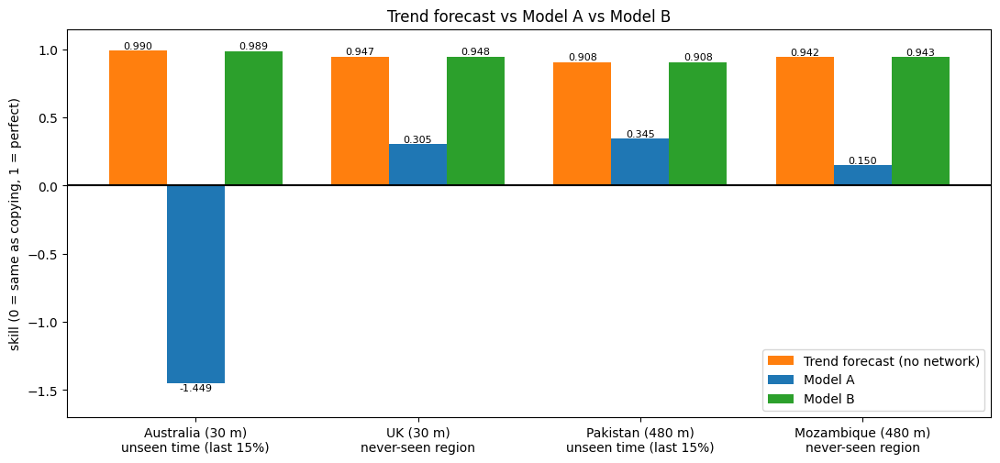

In [ ]:
# Bar chart: trend forecast vs Model A vs Model B
fig, ax = plt.subplots(figsize=(13, 5.5))

columns = ["Skill: trend", "Skill: Model A", "Skill: Model B"]
names = ["Trend forecast (no network)", "Model A", "Model B"]
colours = ["tab:orange", "tab:blue", "tab:green"]

positions = np.arange(len(v2_table))

for number in range(3):
    values = v2_table[columns[number]].astype(float)
    bars = ax.bar(positions + (number - 1) * 0.26, values, width=0.26, color=colours[number], label=names[number])
    ax.bar_label(bars, fmt="%.3f", fontsize=8)

labels = []
for region, part in zip(v2_table["Region"], v2_table["Tested on"]):
    labels.append(region + "\n" + part)

ax.axhline(0, color="black")
ax.set_ylim(-1.7, 1.15)
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel("skill (0 = same as copying, 1 = perfect)")
ax.set_title("Trend forecast vs Model A vs Model B")
ax.legend(loc="lower right")

save_figure(fig, "04_skill_comparison")
plt.show()

Saved figure: 04_error_over_time_with_trend


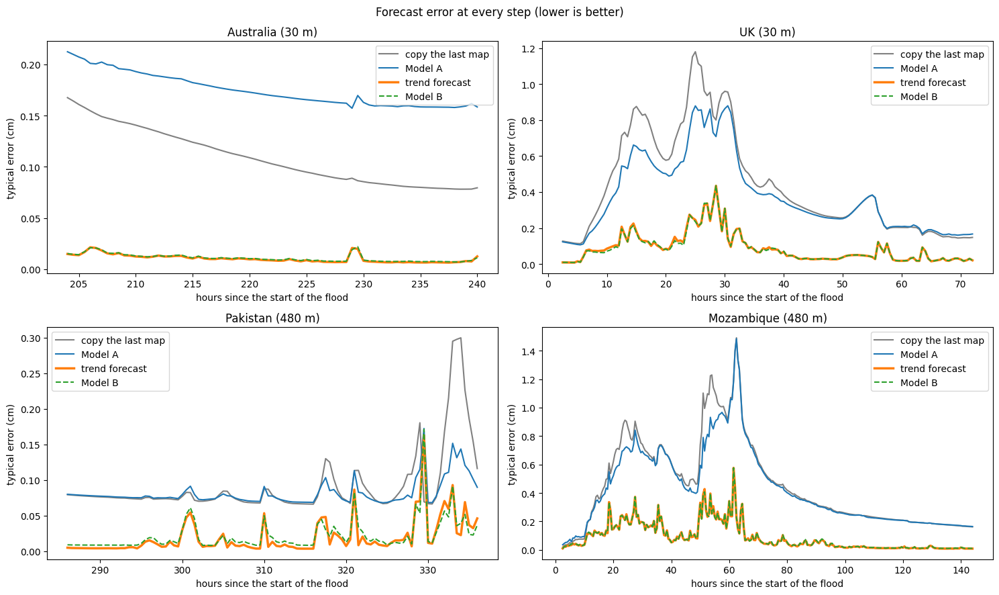

In [ ]:
# Error at every step: copy, trend, Model A, Model B
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ax, dataset in zip(axes.flat, REGION_NAMES):
    model_a = evaluations[dataset]
    model_b = v2_evaluations[dataset]
    hours = model_a["hours"]
    cells = model_a["cells"]

    ax.plot(hours, 100 * np.sqrt(model_a["copy_squared_error"] / cells), color="grey", label="copy the last map")
    ax.plot(hours, 100 * np.sqrt(model_a["model_squared_error"] / cells), color="tab:blue", label="Model A")
    ax.plot(hours, 100 * np.sqrt(trend_squared_errors[dataset] / cells), color="tab:orange", linewidth=2.5, label="trend forecast")
    ax.plot(hours, 100 * np.sqrt(model_b["model_squared_error"] / cells), color="tab:green", linestyle="--", label="Model B")

    ax.set_title(REGION_NAMES[dataset])
    ax.set_xlabel("hours since the start of the flood")
    ax.set_ylabel("typical error (cm)")
    ax.legend()

fig.suptitle("Forecast error at every step (lower is better)")
plt.tight_layout()
save_figure(fig, "04_error_over_time_with_trend")
plt.show()

Saved figure: 04_error_maps


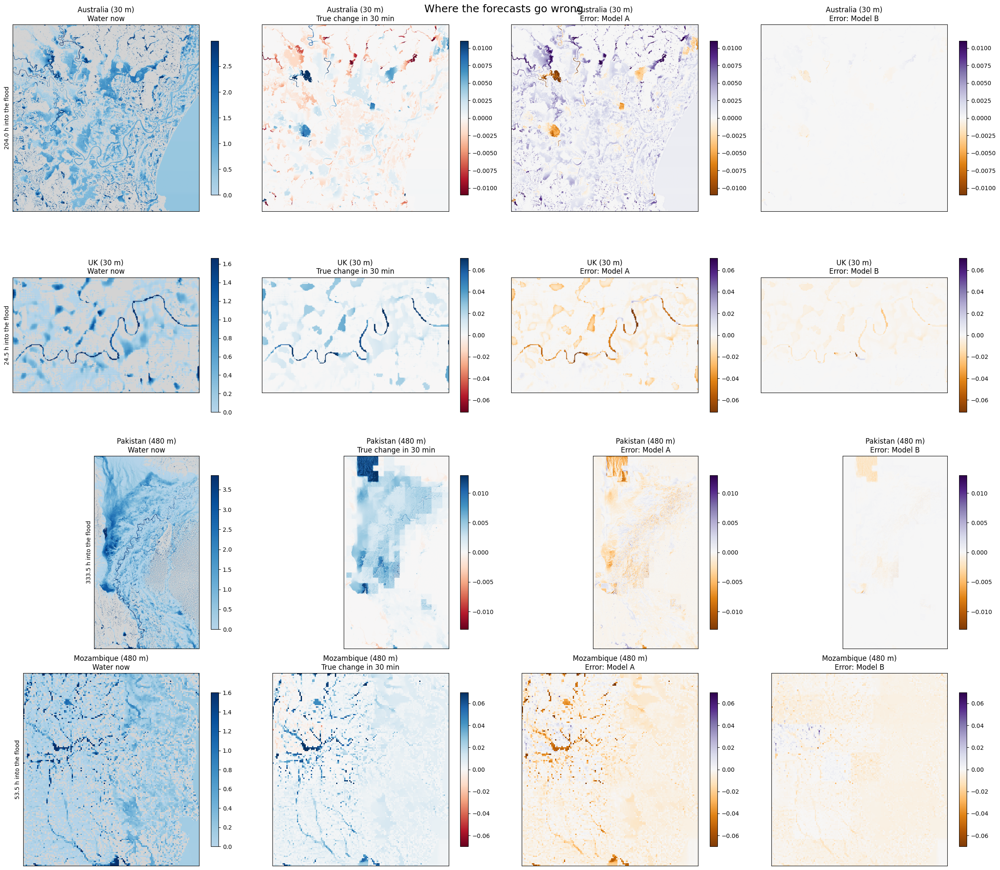

In [ ]:
# Error maps of Model A and Model B (purple = too much water, orange = too little)
column_titles = ["Water now", "True change in 30 min", "Error: Model A", "Error: Model B"]

fig, axes = plt.subplots(4, 4, figsize=(24, 21))

for row, dataset in enumerate(REGION_NAMES):
    model_a = examples[dataset]
    model_b = v2_examples[dataset]

    top_depth = max(np.percentile(model_a["true"], 99), 0.1)
    true_change = model_a["true"] - model_a["last"]
    top_change = max(np.percentile(np.abs(true_change), 99.5), 0.01)

    pictures = [
        show_water(axes[row, 0], model_a["last"], top_depth),
        axes[row, 1].imshow(true_change, cmap="RdBu", vmin=-top_change, vmax=top_change),
        axes[row, 2].imshow(model_a["predicted"] - model_a["true"], cmap="PuOr", vmin=-top_change, vmax=top_change),
        axes[row, 3].imshow(model_b["predicted"] - model_b["true"], cmap="PuOr", vmin=-top_change, vmax=top_change),
    ]

    for column in range(4):
        axes[row, column].set_title(REGION_NAMES[dataset] + "\n" + column_titles[column])
        fig.colorbar(pictures[column], ax=axes[row, column], shrink=0.8)

    axes[row, 0].set_ylabel(str(model_a["step"] * STEP_HOURS) + " h into the flood")

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Where the forecasts go wrong", fontsize=18)
plt.tight_layout()
save_figure(fig, "04_error_maps")
plt.show()

**What this part shows:** at 30 minutes the trend forecast already removes 91% to 99% of the error of copying.
Model A beat copying in 3 of 4 tests but stays far below the trend. Model B matches the trend but does not beat it.
A fair test of the LSTM's memory needs longer forecasts (6 to 24 hours).

## 5. Capsule network: how bad will the flood be in 30 minutes?

Severity of a 64 x 64 tile = share of its normally dry land under more than 30 cm of water:

- None: below 5%
- Minor: 5% to 15%
- Moderate: 15% to 30%
- Severe: above 30%

The capsule network reuses Model A's CNN + ConvLSTM (frozen) and adds capsule layers on top.
Each class gets a small vector (a capsule). The length of the vector = how sure the network is about that class.

In [ ]:
def squash(vectors):
    # Shrink each vector's length to between 0 and 1, keeping its direction
    squared_length = tf.reduce_sum(tf.square(vectors), axis=-1, keepdims=True)
    return squared_length / (1 + squared_length) * vectors / tf.sqrt(squared_length + 1e-7)


class Squash(layers.Layer):
    # A layer that applies squash
    def call(self, vectors):
        return squash(vectors)


class ClassCapsules(layers.Layer):
    # One capsule per class, filled by routing by agreement

    def __init__(self, number_of_classes, capsule_size, routing_rounds=3, **kwargs):
        super().__init__(**kwargs)
        self.number_of_classes = number_of_classes
        self.capsule_size = capsule_size
        self.routing_rounds = routing_rounds

    def build(self, input_shape):
        number_of_inputs = input_shape[1]
        input_size = input_shape[2]

        # One weight matrix for every (small capsule, class capsule) pair
        self.vote_weights = self.add_weight(
            shape=(number_of_inputs, self.number_of_classes, self.capsule_size, input_size),
            initializer=keras.initializers.RandomNormal(stddev=0.05),
            name="vote_weights")

    def call(self, primary_capsules):
        # Every small capsule makes a vote for every class
        votes = tf.einsum("pcoi,bpi->bpco", self.vote_weights, primary_capsules)

        # At the start every vote counts the same
        routing_scores = tf.zeros_like(votes[..., 0])

        for round_number in range(self.routing_rounds):
            # How much each small capsule sends to each class
            coupling = tf.nn.softmax(routing_scores, axis=2)

            # Class capsule = weighted sum of its votes, squashed
            class_capsules = squash(tf.einsum("bpc,bpco->bco", coupling, votes))

            # Votes that agree with the result count more in the next round
            if round_number < self.routing_rounds - 1:
                routing_scores = routing_scores + tf.einsum("bpco,bco->bpc", votes, class_capsules)

        return class_capsules


class CapsuleLength(layers.Layer):
    # Length of each class capsule = how sure the network is
    def call(self, capsules):
        return tf.sqrt(tf.reduce_sum(tf.square(capsules), axis=-1) + 1e-7)


def margin_loss(true_classes, lengths):
    # The right class should be longer than 0.9, the others shorter than 0.1
    correct = true_classes * tf.square(tf.nn.relu(0.9 - lengths))
    wrong = 0.5 * (1 - true_classes) * tf.square(tf.nn.relu(lengths - 0.1))
    return tf.reduce_sum(correct + wrong, axis=-1)

In [ ]:
# Small capsules: 4 types of 8 numbers, at each of 8 x 8 positions
PRIMARY_TYPES = 4
PRIMARY_SIZE = 8
PRIMARY_GRID = TILE_SIZE // 8


def build_severity_model(forecaster):
    # Capsule network on top of Model A's frozen CNN + ConvLSTM

    # Model A's CNN + ConvLSTM part, frozen
    encoder = keras.Model(forecaster.inputs, forecaster.get_layer("memory").output, name="cnn_lstm_encoder")
    encoder.trainable = False

    inputs = keras.Input(shape=(INPUT_STEPS, TILE_SIZE, TILE_SIZE, CHANNELS), name="past_tiles")
    memory = encoder(inputs)

    # Shrink 64 x 64 -> 32 x 32 -> 16 x 16
    x = layers.Conv2D(32, 5, strides=2, padding="same", activation="relu")(memory)
    x = layers.Conv2D(32, 5, strides=2, padding="same", activation="relu")(x)

    # Small capsules at 8 x 8 positions
    x = layers.Conv2D(PRIMARY_TYPES * PRIMARY_SIZE, 3, strides=2, padding="same")(x)
    x = layers.Reshape((PRIMARY_GRID * PRIMARY_GRID * PRIMARY_TYPES, PRIMARY_SIZE))(x)
    primary_capsules = Squash(name="primary_capsules")(x)

    # One capsule per severity class, and its length
    class_capsules = ClassCapsules(len(SEVERITY_NAMES), 16, name="class_capsules")(primary_capsules)
    lengths = CapsuleLength(name="class_lengths")(class_capsules)

    # The model, and a second version that also gives the memory (for Grad-CAM)
    model = keras.Model(inputs, lengths, name="capsule_severity")
    grad_cam_model = keras.Model(inputs, [memory, lengths])
    return model, grad_cam_model

In [ ]:
def tile_labels(region, targets, positions):
    # Severity class of each tile, from the depth map 30 minutes later
    labels = []
    for number in range(len(targets)):
        target_step, top, left = positions[number]
        dry_land = region["dry_land"][top:top + TILE_SIZE, left:left + TILE_SIZE]
        labels.append(severity_class(flooded_share(targets[number][:, :, 0], dry_land)))
    return np.array(labels)


# Labels for the training and checking tiles
for pair in PAIRS:
    data = tiles[pair["name"]]
    region = regions[pair["train"]]
    data["train_labels"] = tile_labels(region, data["train_targets"], data["train_positions"])
    data["validation_labels"] = tile_labels(region, data["validation_targets"], data["validation_positions"])

# How many training tiles are in each class
label_counts = pd.DataFrame(index=SEVERITY_NAMES)
for pair in PAIRS:
    label_counts[pair["name"] + " model"] = np.bincount(tiles[pair["name"]]["train_labels"], minlength=4)
display(label_counts)

,30m model,480m model
None,1942,234
Minor,1619,562
Moderate,359,1318
Severe,80,1886


In [ ]:
# Load (or train) the capsule network for each map scale
severity_models = {}
severity_grad_cam_models = {}

for pair in PAIRS:
    data = tiles[pair["name"]]
    weights_path = MODEL_DIR + "/capsule_" + pair["name"] + ".weights.h5"

    model, grad_cam_model = build_severity_model(forecasters[pair["name"]])
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=margin_loss,
                  metrics=[keras.metrics.CategoricalAccuracy(name="accuracy")])

    if TRAIN_NEW or not os.path.exists(weights_path):
        print("Training the capsule network", pair["name"])

        # Rare classes count more, so the network can't just answer "None"
        counts = np.bincount(data["train_labels"], minlength=4)
        class_weights = len(data["train_labels"]) / (4 * np.maximum(counts, 1))
        sample_weights = class_weights[data["train_labels"]]

        stop_early = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

        model.fit(
            data["train_inputs"], keras.utils.to_categorical(data["train_labels"], 4),
            sample_weight=sample_weights,
            validation_data=(data["validation_inputs"], keras.utils.to_categorical(data["validation_labels"], 4)),
            epochs=30, batch_size=32, callbacks=[stop_early], verbose=2)

        model.save_weights(weights_path)
    else:
        print("Loading the capsule network", pair["name"])
        model.load_weights(weights_path)

    severity_models[pair["name"]] = model
    severity_grad_cam_models[pair["name"]] = grad_cam_model

Loading the capsule network 30m
Loading the capsule network 480m


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 16 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
# Test tiles: last 15% of the training floods, and the whole of the never-seen floods
test_tiles = {}

for pair in PAIRS:
    train_region = regions[pair["train"]]
    test_region = regions[pair["test"]]

    parts = [
        (pair["train"], train_region["validation_end"], train_region["number_of_maps"]),
        (pair["test"], FIRST_TARGET, test_region["number_of_maps"]),
    ]

    for dataset, first_target, last_target in parts:
        region = regions[dataset]
        inputs, targets, positions = make_test_tiles(region, first_target, last_target, TEST_TILES)

        # Capsule network's answer, and Model A's forecast (used by the rules)
        lengths = severity_models[pair["name"]].predict(inputs, batch_size=32, verbose=0)
        forecast = forecasters[pair["name"]].predict(inputs, batch_size=32, verbose=0)

        test_tiles[dataset] = {
            "inputs": inputs,
            "targets": targets,
            "positions": positions,
            "labels": tile_labels(region, targets, positions),
            "capsule_lengths": lengths,
            "capsule_classes": np.argmax(lengths, axis=1),
            "forecast": forecast,
        }

        print(REGION_NAMES[dataset], "test tiles:", len(inputs))

Australia (30 m) test tiles: 1000
UK (30 m) test tiles: 1000
Pakistan (480 m) test tiles: 1000
Mozambique (480 m) test tiles: 1000


Saved figure: 05_capsule_confusion


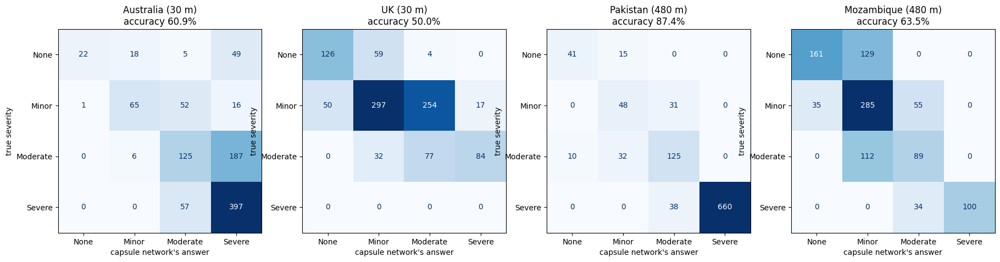

In [ ]:
# Confusion matrix: true class (rows) vs the network's answer (columns)
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))

for ax, dataset in zip(axes, REGION_NAMES):
    data = test_tiles[dataset]
    matrix = confusion_matrix(data["labels"], data["capsule_classes"], labels=range(4))
    ConfusionMatrixDisplay(matrix, display_labels=SEVERITY_NAMES).plot(ax=ax, colorbar=False, cmap="Blues")

    accuracy = np.mean(data["labels"] == data["capsule_classes"])
    ax.set_title(REGION_NAMES[dataset] + "\naccuracy " + str(round(100 * accuracy, 1)) + "%")
    ax.set_xlabel("capsule network's answer")
    ax.set_ylabel("true severity")

save_figure(fig, "05_capsule_confusion")
plt.show()

## 6. Grad-CAM: where does the model look?

1. Pick one number to explain (total predicted water, or the length of the chosen class capsule)
2. Find how much that number changes when each memory map of the ConvLSTM changes (the gradient)
3. Average each gradient map into one weight per memory map
4. Heat map = weighted sum of the memory maps, keeping only the positive part

Bright = important. For big maps we zoom into a window of up to 256 x 256 squares, because a whole map doesn't fit in GPU memory.

In [ ]:
def grad_cam(grad_cam_model, model_input, class_number=None):
    # Heat map (0 to 1) over the ConvLSTM memory
    # class_number = None explains the total predicted water, otherwise the length of that class capsule

    with tf.GradientTape() as tape:
        memory, output = grad_cam_model(model_input, training=False)
        if class_number is None:
            explained = tf.reduce_sum(output)
        else:
            explained = output[0, class_number]

    # How much the explained number changes when the memory changes
    gradients = tape.gradient(explained, memory)

    # One weight per memory map: its average gradient
    channel_weights = tf.reduce_mean(gradients, axis=(1, 2))

    # Weighted sum of the memory maps, keeping the positive part
    heatmap = tf.nn.relu(tf.reduce_sum(memory * channel_weights[:, None, None, :], axis=-1))[0].numpy()

    # Scale to 0 - 1
    return heatmap / (heatmap.max() + 1e-8)


# Free memory from the whole-map tests
whole_map_forecasters = {}
gc.collect()

# Largest window size for Grad-CAM
GRAD_CAM_WINDOW = 256

# Which model (30m or 480m) belongs to each flood
model_of_region = {}
for pair in PAIRS:
    model_of_region[pair["train"]] = pair["name"]
    model_of_region[pair["test"]] = pair["name"]


def grad_cam_window(example):
    # Window centred on the busiest area of true change, kept inside the map
    rows, columns = example["true"].shape
    height = min(GRAD_CAM_WINDOW, rows)
    width = min(GRAD_CAM_WINDOW, columns)

    # Smooth the change map so the centre is a busy area, not a single square
    change = np.abs(example["true"] - example["last"])
    busy = uniform_filter(change, size=31)
    centre_row, centre_column = np.unravel_index(np.argmax(busy), busy.shape)

    top = int(np.clip(centre_row - height // 2, 0, rows - height))
    left = int(np.clip(centre_column - width // 2, 0, columns - width))
    return top, left, height, width

Saved figure: 06_grad_cam_forecaster


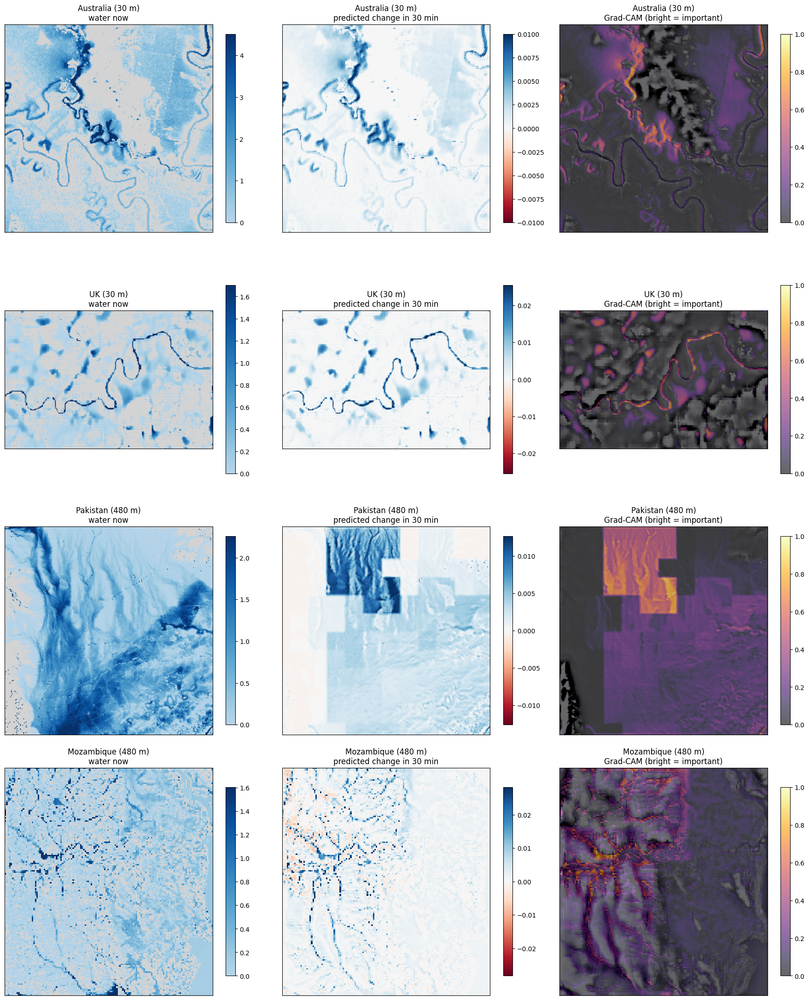

In [ ]:
# Grad-CAM of Model A, one row per flood
fig, axes = plt.subplots(4, 3, figsize=(18, 22))

for row, dataset in enumerate(REGION_NAMES):
    region = regions[dataset]
    example = examples[dataset]
    top, left, height, width = grad_cam_window(example)

    # Model A at the window size, with the trained weights
    window_forecaster = build_forecaster(height, width)
    window_forecaster.set_weights(forecasters[model_of_region[dataset]].get_weights())
    grad_cam_model = keras.Model(window_forecaster.input,
                                 [window_forecaster.get_layer("memory").output, window_forecaster.output])

    model_input = make_input(region, example["step"] - 1, top, left, height, width)[None]
    heatmap = grad_cam(grad_cam_model, model_input)

    # The same window cut out of the maps
    last = example["last"][top:top + height, left:left + width]
    predicted_change = example["predicted"][top:top + height, left:left + width] - last

    top_depth = max(np.percentile(example["true"][top:top + height, left:left + width], 99), 0.1)
    top_change = max(np.percentile(np.abs(predicted_change), 99.5), 0.01)

    picture = show_water(axes[row, 0], last, top_depth)
    axes[row, 0].set_title(REGION_NAMES[dataset] + "\nwater now")
    fig.colorbar(picture, ax=axes[row, 0], shrink=0.8)

    picture = axes[row, 1].imshow(predicted_change, cmap="RdBu", vmin=-top_change, vmax=top_change)
    axes[row, 1].set_title(REGION_NAMES[dataset] + "\npredicted change in 30 min")
    fig.colorbar(picture, ax=axes[row, 1], shrink=0.8)

    # Heat map on top of the ground height
    axes[row, 2].imshow(region["local_height"][top:top + height, left:left + width], cmap="Greys_r", vmin=-2, vmax=2)
    picture = axes[row, 2].imshow(heatmap, cmap="inferno", alpha=0.6, vmin=0, vmax=1)
    axes[row, 2].set_title(REGION_NAMES[dataset] + "\nGrad-CAM (bright = important)")
    fig.colorbar(picture, ax=axes[row, 2], shrink=0.8)

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
save_figure(fig, "06_grad_cam_forecaster")
plt.show()

Saved figure: 06_grad_cam_capsule


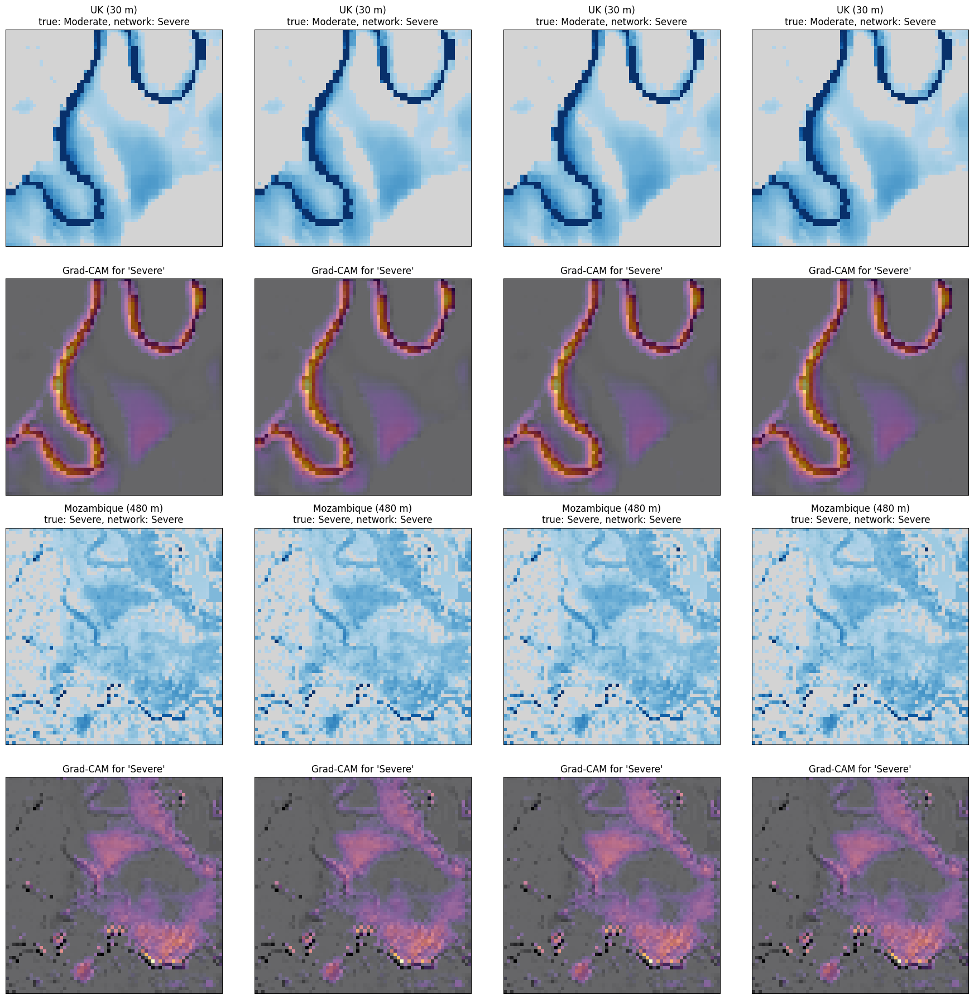

In [ ]:
# Grad-CAM of the capsule network, on the 4 most flooded tiles of each never-seen flood
fig, axes = plt.subplots(4, 4, figsize=(18, 18))
row = 0

for pair in PAIRS:
    dataset = pair["test"]
    data = test_tiles[dataset]
    region = regions[dataset]

    # Flooded share of every test tile, and the 4 highest
    shares = []
    for number in range(len(data["targets"])):
        step, top, left = data["positions"][number]
        dry_land = region["dry_land"][top:top + TILE_SIZE, left:left + TILE_SIZE]
        shares.append(flooded_share(data["targets"][number][:, :, 0], dry_land))
    chosen = np.argsort(shares)[-4:]

    for column in range(4):
        tile = chosen[column]
        chosen_class = data["capsule_classes"][tile]
        heatmap = grad_cam(severity_grad_cam_models[pair["name"]], data["inputs"][tile:tile + 1], chosen_class)

        # Top: the water. Bottom: the heat map.
        show_water(axes[row, column], data["inputs"][tile, -1, :, :, 0], 2.0)
        axes[row, column].set_title(REGION_NAMES[dataset] + "\ntrue: " + SEVERITY_NAMES[data["labels"][tile]]
                                    + ", network: " + SEVERITY_NAMES[chosen_class])

        axes[row + 1, column].imshow(data["inputs"][tile, -1, :, :, 0], cmap="Greys", vmin=0, vmax=2)
        axes[row + 1, column].imshow(heatmap, cmap="inferno", alpha=0.6, vmin=0, vmax=1)
        axes[row + 1, column].set_title("Grad-CAM for '" + SEVERITY_NAMES[chosen_class] + "'")

    row = row + 2

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
save_figure(fig, "06_grad_cam_capsule")
plt.show()

## 7. Written rules (NeuroSymbolic part)

The neural network gives a severity class. Three written rules check it, using facts measured from the tile and from Model A's forecast. Every final answer comes with a written reason.

1. **No water, no flood**: under 1% of the land is flooded now and in the forecast -> None
2. **Rising water**: the forecast has at least as much flooding as now and more than 1 mm/h of rain fell in the last hour -> the class can't be lower than the current level
3. **Agree with the forecast**: the network is more than one class away from the class of the forecast map -> use the forecast map's class

The water-balance rule in part 3a is the other written (symbolic) rule.

In [ ]:
# Limits used by the rules
ALMOST_DRY_SHARE = 0.01
RAIN_RULE_MM_PER_HOUR = 1.0


def apply_rules(network_class, share_now, share_forecast, rain_last_hour):
    # Check the network's class with the three rules; return the final class and the reason

    now_class = severity_class(share_now)
    forecast_class = severity_class(share_forecast)

    # Rule 1: no water, no flood
    if share_now < ALMOST_DRY_SHARE and share_forecast < ALMOST_DRY_SHARE:
        return 0, "Rule 1: under 1% of the land flooded now and in the forecast, so None"

    # Rule 2: rising water during rain can't be less severe than now
    if share_forecast >= share_now and rain_last_hour > RAIN_RULE_MM_PER_HOUR and network_class < now_class:
        return now_class, "Rule 2: water rising during rain, so at least " + SEVERITY_NAMES[now_class] + " (the current level)"

    # Rule 3: the network and the forecast map are more than one class apart
    if abs(network_class - forecast_class) > 1:
        return forecast_class, ("Rule 3: network said " + SEVERITY_NAMES[network_class] + " but the forecast map says "
                                + SEVERITY_NAMES[forecast_class] + ", so the forecast map wins")

    return network_class, "No rule needed: the network's answer agrees with the rules"

In [ ]:
# Apply the rules to every test tile
for dataset in test_tiles:
    data = test_tiles[dataset]
    region = regions[dataset]

    final_classes = []
    forecast_classes = []
    reasons = []

    for tile in range(len(data["positions"])):
        target_step, top, left = data["positions"][tile]
        dry_land = region["dry_land"][top:top + TILE_SIZE, left:left + TILE_SIZE]

        # Facts the rules use
        share_now = flooded_share(data["inputs"][tile, -1, :, :, 0], dry_land)
        share_forecast = flooded_share(data["forecast"][tile, :, :, 0], dry_land)
        rain_last_hour = data["inputs"][tile, -2:, :, :, 1].mean() * RAIN_SCALE

        final_class, reason = apply_rules(data["capsule_classes"][tile], share_now, share_forecast, rain_last_hour)

        final_classes.append(final_class)
        forecast_classes.append(severity_class(share_forecast))
        reasons.append(reason)

    data["final_classes"] = np.array(final_classes)
    data["forecast_classes"] = np.array(forecast_classes)
    data["reasons"] = reasons

In [ ]:
# Accuracy with and without the rules
rule_rows = []

for dataset in test_tiles:
    data = test_tiles[dataset]
    rule_rows.append({
        "Region": REGION_NAMES[dataset],
        "Test tiles": len(data["labels"]),
        "Capsule network alone (%)": round(100 * np.mean(data["capsule_classes"] == data["labels"]), 1),
        "Class of the forecast map alone (%)": round(100 * np.mean(data["forecast_classes"] == data["labels"]), 1),
        "Capsule network + rules (%)": round(100 * np.mean(data["final_classes"] == data["labels"]), 1),
        "Decisions changed by the rules (%)": round(100 * np.mean(data["final_classes"] != data["capsule_classes"]), 1),
    })

rule_table = pd.DataFrame(rule_rows)
display(rule_table)
save_table(rule_table, "07_neurosymbolic_accuracy")

,Region,Test tiles,Capsule network alone (%),Class of the forecast map alone (%),Capsule network + rules (%),Decisions changed by the rules (%)
0,Australia (30 m),1000,60.9,99.8,67.9,7.0
1,UK (30 m),1000,50.0,99.1,56.1,6.1
2,Pakistan (480 m),1000,87.4,99.9,89.1,1.7
3,Mozambique (480 m),1000,63.5,99.5,70.7,7.2


Saved table: 07_neurosymbolic_accuracy


In [ ]:
# How often each rule made the final decision
reason_rows = []

for dataset in test_tiles:
    reasons = test_tiles[dataset]["reasons"]

    # The rule name is the text before the ":" in each reason
    rule_names = []
    for reason in reasons:
        rule_names.append(reason.split(":")[0])

    row = {"Region": REGION_NAMES[dataset]}
    for rule in ["No rule needed", "Rule 1", "Rule 2", "Rule 3"]:
        row[rule] = rule_names.count(rule)
    reason_rows.append(row)

reason_table = pd.DataFrame(reason_rows)
display(reason_table)
save_table(reason_table, "07_rules_used")

,Region,No rule needed,Rule 1,Rule 2,Rule 3
0,Australia (30 m),930,49,0,21
1,UK (30 m),939,0,40,21
2,Pakistan (480 m),983,0,7,10
3,Mozambique (480 m),824,134,42,0


Saved table: 07_rules_used


In [ ]:
# Some example decisions with their reasons (never-seen floods)
example_rows = []

for pair in PAIRS:
    data = test_tiles[pair["test"]]

    # First the tiles where a rule changed the answer, then a few others
    changed = np.where(data["final_classes"] != data["capsule_classes"])[0]
    unchanged = np.where(data["final_classes"] == data["capsule_classes"])[0]
    chosen = list(changed[:3]) + list(unchanged[:2])

    for tile in chosen:
        example_rows.append({
            "Region": REGION_NAMES[pair["test"]],
            "Hours into flood": data["positions"][tile][0] * STEP_HOURS,
            "True severity": SEVERITY_NAMES[data["labels"][tile]],
            "Capsule network": SEVERITY_NAMES[data["capsule_classes"][tile]],
            "Final decision": SEVERITY_NAMES[data["final_classes"][tile]],
            "Reason": data["reasons"][tile],
        })

example_table = pd.DataFrame(example_rows)
pd.set_option("display.max_colwidth", None)
display(example_table)
save_table(example_table, "07_example_decisions")

,Region,Hours into flood,True severity,Capsule network,Final decision,Reason
0,UK (30 m),11.0,Minor,None,Minor,"Rule 2: water rising during rain, so at least Minor (the current level)"
1,UK (30 m),26.5,Minor,Severe,Minor,"Rule 3: network said Severe but the forecast map says Minor, so the forecast map wins"
2,UK (30 m),10.0,Minor,None,Minor,"Rule 2: water rising during rain, so at least Minor (the current level)"
3,UK (30 m),47.5,Minor,Minor,Minor,No rule needed: the network's answer agrees with the rules
4,UK (30 m),11.0,None,None,None,No rule needed: the network's answer agrees with the rules
5,Mozambique (480 m),14.0,None,Minor,None,"Rule 1: under 1% of the land flooded now and in the forecast, so None"
6,Mozambique (480 m),56.5,Moderate,Minor,Moderate,"Rule 2: water rising during rain, so at least Moderate (the current level)"
7,Mozambique (480 m),79.5,Severe,Moderate,Severe,"Rule 2: water rising during rain, so at least Severe (the current level)"
8,Mozambique (480 m),40.5,Minor,Minor,Minor,No rule needed: the network's answer agrees with the rules
9,Mozambique (480 m),76.0,Severe,Moderate,Moderate,No rule needed: the network's answer agrees with the rules


Saved table: 07_example_decisions


## 8. Summary

In [ ]:
# One table with the main numbers
summary_rows = []

for dataset in REGION_NAMES:
    forecast_row = v2_table[v2_table["Region"] == REGION_NAMES[dataset]].iloc[0]
    rule_row = rule_table[rule_table["Region"] == REGION_NAMES[dataset]].iloc[0]

    summary_rows.append({
        "Region": REGION_NAMES[dataset],
        "Tested on": forecast_row["Tested on"],
        "Skill: trend forecast": forecast_row["Skill: trend"],
        "Skill: Model A": forecast_row["Skill: Model A"],
        "Skill: Model B": forecast_row["Skill: Model B"],
        "Severity: capsule (%)": rule_row["Capsule network alone (%)"],
        "Severity: capsule + rules (%)": rule_row["Capsule network + rules (%)"],
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)
save_table(summary_table, "08_summary")

,Region,Tested on,Skill: trend forecast,Skill: Model A,Skill: Model B,Severity: capsule (%),Severity: capsule + rules (%)
0,Australia (30 m),unseen time (last 15%),0.990,-1.449,0.989,60.9,67.9
1,UK (30 m),never-seen region,0.947,0.305,0.948,50.0,56.1
2,Pakistan (480 m),unseen time (last 15%),0.908,0.345,0.908,87.4,89.1
3,Mozambique (480 m),never-seen region,0.942,0.150,0.943,63.5,70.7


Saved table: 08_summary


In [ ]:
# List everything this notebook saved on Drive
for folder in [MODEL_DIR, FIGURE_DIR, TABLE_DIR]:
    print(folder)
    for file_name in sorted(os.listdir(folder)):
        print("   ", file_name)

/content/drive/MyDrive/Flood_project/models
    capsule_30m.weights.h5
    capsule_480m.weights.h5
    forecaster_30m.weights.h5
    forecaster_480m.weights.h5
    forecaster_v2_30m.weights.h5
    forecaster_v2_480m.weights.h5
/content/drive/MyDrive/Flood_project/model_outputs/figures
    02_training_progress.png
    03_error_over_time.png
    03_forecast_maps.png
    03_skill_per_region.png
    03_water_balance_check.png
    04_capsule_confusion.png
    04_error_maps.png
    04_error_over_time_with_trend.png
    04_skill_comparison.png
    05_capsule_confusion.png
    05_grad_cam_capsule.png
    05_grad_cam_forecaster.png
    06_grad_cam_capsule.png
    06_grad_cam_forecaster.png
    08_error_maps.png
    08_error_over_time_with_trend.png
    08_skill_comparison.png
    P1_skill_comparison.png
    P2_error_over_time.png
    P3a_error_maps_30m.png
    P3b_error_maps_480m.png
    P4_water_balance.png
    P5_capsule_confusion.png
    P6_grad_cam_forecaster.png
/content/drive/MyDrive/Floo